The three ODE solvers which will be used are Runge-Kutta 45 (RK45) which is a standard explicit solver, Radau, which is an implicit Runge-Kutta solver, and LSODA, which is an adaptive solver which in addition to having adaptive timesteps also switches between the non-stiff Adams method and the stiff BDF method depending on how fast the stiffness it detects.

In [1]:
import time

from matplotlib import pyplot as plt
import numpy as np
import pandas as pd
from scipy.signal import find_peaks
from scipy.integrate import solve_ivp

#SETUP

### Lotka-Volterra ###

def lotka_volterra(t,y,a,b,c,d):
    R,F = y

    dRdt = a*R-b*F*R
    dFdt = c*R*F-d*F

    return [dRdt, dFdt]

a = 0.4
b = 0.001
c = 0.001
d = 0.9

# Initial conditions
y0_LV = [600, 400]

# Time interval
t_LV = [0, 30]

# Analytical fixed points
fixPts_LV = np.array([[0,0], [900, 400]])
n_fp_LV = fixPts_LV.shape[0]


### BZ ###

def Belousov_Zhabotinsky(t, y, alpha, beta, gamma):
    x1,x2,x3 = y

    dx1dt = alpha*(x2+x1*(1-beta*x1-x2))
    dx2dt = 1/alpha*(x3-(1+x1)*x2)
    dx3dt = gamma*(x1-x3)

    return [dx1dt, dx2dt, dx3dt]

# Time interval
t_BZ = [0, 1000]

# Initial conditions
y0_BZ = [1, 2, 3]

# Constants
alpha = 77.27
beta_BZ = 8.375*10**(-6)
gamma = 1.161

# Analytical fixed points
fixPts_BZ = np.array([[0,0,0], [488.88, 0.99796, 488.18], [-489.18, 1.0020, -489.18]])
n_fp_BZ = fixPts_BZ.shape[0]


### Lorenz ###

def lorenz(t,y,sigma,rho,beta):
    [x1, x2, x3] = y

    dx1dt = sigma*(x2-x1)
    dx2dt = x1*(rho-x3)-x2
    dx3dt = x1*x2-beta*x3

    return [dx1dt, dx2dt, dx3dt]

# Constants
beta_LZ = 8/3
rho = 50
sigma = 10

# Initial conditions
x0_LZ = [-8, 8, 27]

# Time interval
t_Lorenz = [0,20]

# Analytical fixed points
fixPts_Lorenz = np.array([[0,0,0], [7*np.sqrt(8/3), 7*np.sqrt(8/3), 49], [-7*np.sqrt(8/3), -7*np.sqrt(8/3), 49]])
n_fp_Lorenz = fixPts_Lorenz.shape[0]

In [2]:
### LOW TOLERANCE RUNS ###
# For later comparisons
rtol = 1e-11
atol = 1e-14

### Lotka-Volterra 

# LV - RK45
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='RK45',
    args=(a,b,c,d),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LV_RK45 = sol.y[:,-1]

# LV - Radau
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='Radau',
    args=(a,b,c,d),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LV_Radau = sol.y[:,-1]

# LV - LSODA
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='LSODA',
    args=(a,b,c,d),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LV_LSODA = sol.y[:,-1]


### Belousoz-Zhabotinsky

# BZ - RK45
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=Belousov_Zhabotinsky,
    t_span=t_BZ,
    y0=y0_BZ,
    method='RK45',
    args=(alpha,beta_BZ,gamma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_BZ_RK45 = sol.y[:,-1]

# BZ - Radau
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=Belousov_Zhabotinsky,
    t_span=t_BZ,
    y0=y0_BZ,
    method='Radau',
    args=(alpha,beta_BZ,gamma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_BZ_Radau = sol.y[:,-1]

# BZ - LSODA
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=Belousov_Zhabotinsky,
    t_span=t_BZ,
    y0=y0_BZ,
    method='LSODA',
    args=(alpha,beta_BZ,gamma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_BZ_LSODA = sol.y[:,-1]


### Lorenz ###

# LZ - RK45
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lorenz,
    t_span=t_Lorenz,
    y0=x0_LZ,
    method='RK45',
    args=(beta_LZ,rho,sigma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LZ_RK45 = sol.y[:,-1]

# LZ - Radau
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lorenz,
    t_span=t_Lorenz,
    y0=x0_LZ,
    method='Radau',
    args=(beta_LZ,rho,sigma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LZ_Radau = sol.y[:,-1]

# LZ - LSODA
endPts = []
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lorenz,
    t_span=t_Lorenz,
    y0=x0_LZ,
    method='LSODA',
    args=(beta_LZ,rho,sigma),
    dense_output=True,
    rtol=rtol,
    atol=atol
)
tEnd = time.perf_counter()
endPt_LZ_LSODA = sol.y[:,-1]




In [3]:
# Default Tolerance Runs

runtimes = []
nsteps = []
errors = []
nfevOverSteps = []

### Lotka-Volterra

# RK45
t_eval = np.linspace(t_LV[0],t_LV[1],1000)
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='RK45',
    args=(a,b,c,d),
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]

tSolv_RK45 = tEnd-tStart
y_LV_RK45 = sol.sol
steps_RK45 =  len(sol.t)-1
error_RK45 = np.linalg.norm(endPt-endPt_LV_RK45) 
nfevOverSteps_RK45 = sol.nfev/steps_RK45


# Radau
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='Radau',
    args=(a,b,c,d),
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_LV_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = np.linalg.norm(endPt-endPt_LV_Radau)
nfevOverSteps_Radau = sol.nfev/steps_Radau

# LSODA
tStart = time.perf_counter() 
sol = solve_ivp(
    fun=lotka_volterra,
    t_span=t_LV,
    y0=y0_LV,
    method='LSODA',
    args=(a,b,c,d),
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_LV_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = np.linalg.norm(endPt-endPt_LV_LSODA)
nfevOverSteps_LSODA = sol.nfev/steps_LSODA

# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "End Point Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver  Runtime [s]  Steps  End Point Error  nfev/step
  RK45     0.004023     18         4.811279   7.444444
 Radau     0.017533     37         0.093796   9.810811
 LSODA     0.003129     60        10.949303   2.250000


RK45 and LSODA seem to be similar in speed for and # of function evaluations per step. Radau slower and makes more calculations per step.

In [4]:
### BZ

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0_BZ,
    args=(alpha, beta_BZ, gamma),
    method="RK45",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_BZ_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)-1
error_RK45 = np.linalg.norm(endPt-endPt_BZ_RK45)
nfevOverSteps_RK45 = sol.nfev/steps_RK45


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0_BZ,
    args=(alpha, beta_BZ, gamma),
    method="Radau",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_BZ_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = np.linalg.norm(endPt-endPt_BZ_Radau)
nfevOverSteps_Radau = sol.nfev/steps_Radau


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = Belousov_Zhabotinsky,
    t_span = t_BZ,
    y0 = y0_BZ,
    args=(alpha, beta_BZ, gamma),
    method="LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_BZ_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = np.linalg.norm(endPt-endPt_BZ_LSODA)
nfevOverSteps_LSODA = sol.nfev/steps_LSODA


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "End Point Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver  Runtime [s]   Steps  End Point Error  nfev/step
  RK45   132.340131 1636617         0.003154   6.955214
 Radau     0.279366     577         0.014513  10.863085
 LSODA     0.043241    1666         1.824004   2.321729


In [5]:
### Lorenz

# RK45

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0_LZ,
    args = (sigma, rho, beta_LZ),
    method = "RK45",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_Lorenz_RK45 = sol.sol

tSolv_RK45 = tEnd-tStart
steps_RK45 =  len(sol.t)-1
error_RK45 = np.linalg.norm(endPt-endPt_LZ_RK45)
nfevOverSteps_RK45 = sol.nfev/steps_RK45


# Radau

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0_LZ,
    args = (sigma, rho, beta_LZ),
    method = "Radau",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_Lorenz_Radau = sol.sol

tSolv_Radau = tEnd-tStart
steps_Radau =  len(sol.t)-1
error_Radau = np.linalg.norm(endPt-endPt_LZ_Radau)
nfevOverSteps_Radau = sol.nfev/steps_Radau


# LSODA

tStart = time.perf_counter()
sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0_LZ,
    args = (sigma, rho, beta_LZ),
    method = "LSODA",
    dense_output=True
)
tEnd = time.perf_counter()
endPt = sol.y[:,-1]
y_Lorenz_LSODA = sol.sol

tSolv_LSODA = tEnd-tStart
steps_LSODA =  len(sol.t)-1
error_LSODA = np.linalg.norm(endPt-endPt_LZ_LSODA)
nfevOverSteps_LSODA = sol.nfev/steps_LSODA


# For table
data = {
    "Solver": ["RK45", "Radau", "LSODA"],
    "Runtime [s]": [tSolv_RK45, tSolv_Radau, tSolv_LSODA],
    "Steps": [steps_RK45, steps_Radau, steps_LSODA],
    "End Point Error": [error_RK45, error_Radau, error_LSODA],
    "nfev/step": [nfevOverSteps_RK45, nfevOverSteps_Radau, nfevOverSteps_LSODA]
}

df = pd.DataFrame(data)

print(df.to_string(index=False))

Solver  Runtime [s]  Steps  End Point Error  nfev/step
  RK45     0.041582    302        47.638213   8.112583
 Radau     0.227170    577        17.871081   8.864818
 LSODA     0.033605   1457        27.224973   2.066575


## Choice of Solvers
From these statistics, we can choose a solver for each system
For the Lotka-Volterra simulation, Radau has the best accuracy by far, while having the longest run-time. But even if its run time is the longest out of the solver, its runtime is still very short. Therefore, Radau is our choice for solver for Lotka-Volterra.

For the Belousov-Zhabotinsky simulation, RK45 has the best accuracy, but the runtime is by far too long. The best compromise for runtime and accuracy is again Radau for the BZ simulation.

For the Lorenz simulation, once again the Radau solver had best performance accuracy-wise. The runtime was short for all solvers, so it is not a limiting factor in the decision making. Therefore, the Radau solver is chosen for this system as well.  

Radau is good for stiff systems such as the Belousov-Zhabotinsky as it is a solver with strong stability. 

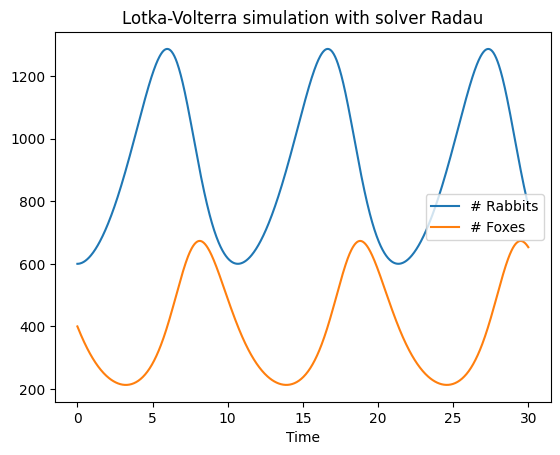

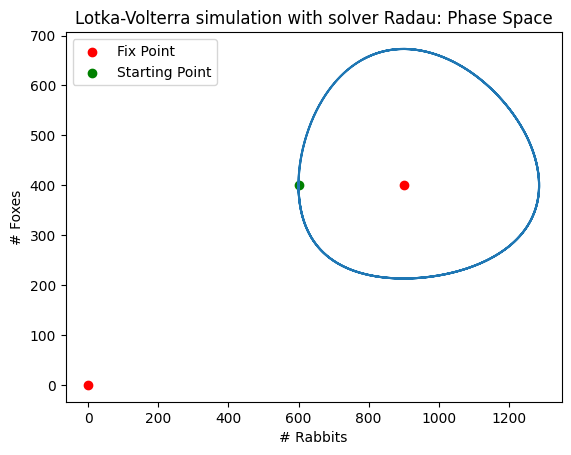

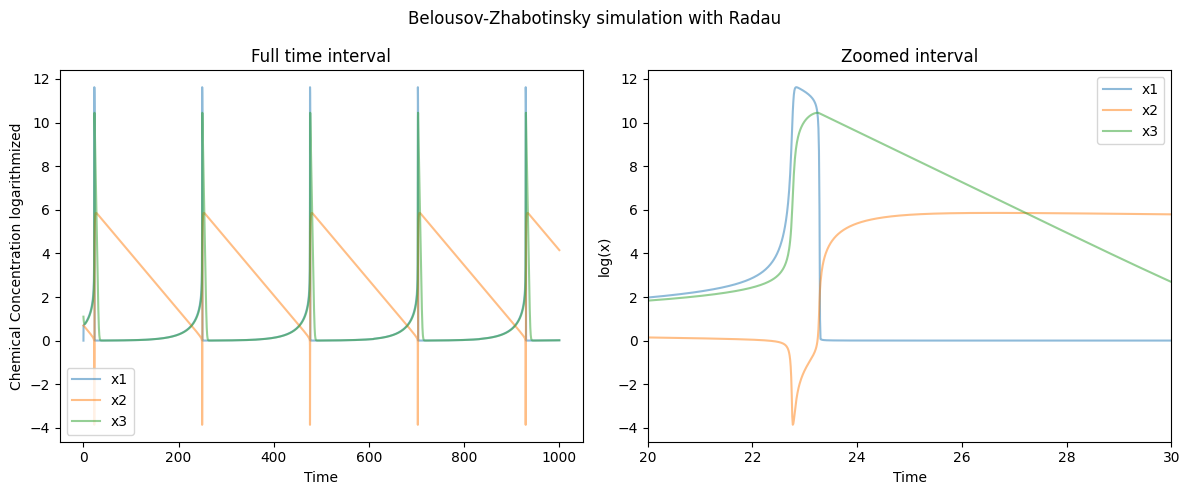

C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\797838365.py:70: RuntimeWarning: divide by zero encountered in log
  fixPtsLogged = np.log(fixPts_BZ)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\797838365.py:70: RuntimeWarning: invalid value encountered in log
  fixPtsLogged = np.log(fixPts_BZ)


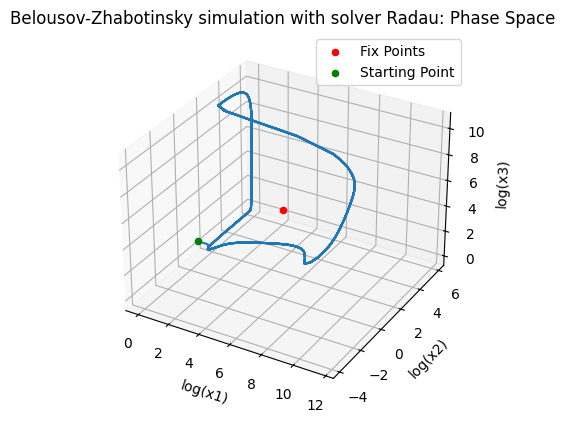

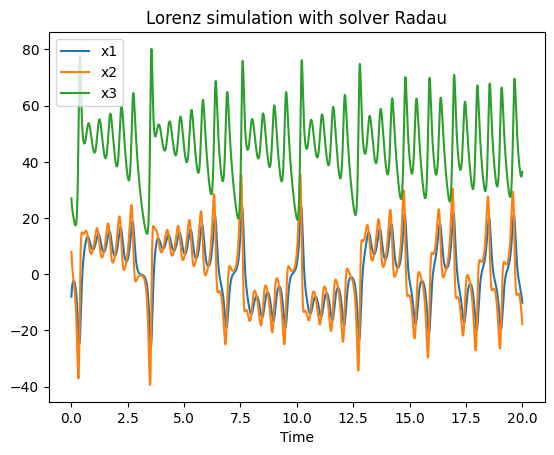

Text(0.5, 0.92, 'Lorenz simulation with solver Radau: Phase Space')

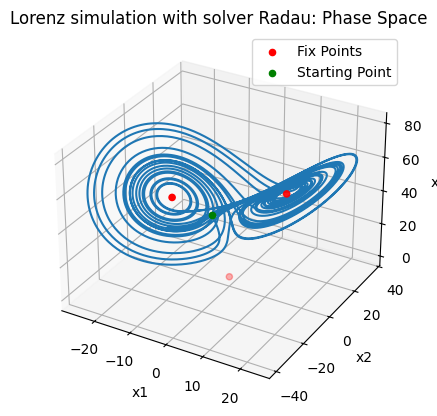

In [6]:
# Lotka-Volterra Plots

# Time Series
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_Radau(t_plot_LV) # Choose method here
plt.figure()
plt.title('Lotka-Volterra simulation with solver Radau')
plt.plot(t_plot_LV, y_plot_LV[0,:],label='# Rabbits')
plt.plot(t_plot_LV, y_plot_LV[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
plt.figure()
plt.title("Lotka-Volterra simulation with solver Radau: Phase Space")
plt.xlabel("# Rabbits")
plt.ylabel("# Foxes")
plt.plot(y_plot_LV[0,:], y_plot_LV[1,:])
plt.scatter(*fixPts_LV.T, label="Fix Point", color="r") # Fix point
plt.scatter(y_plot_LV[0,0],y_plot_LV[1,0],label="Starting Point", color="g")
plt.legend()
plt.show()

# Belousov-Zhabotinsky Plots

# Time Series
t_plot_BZ = np.linspace(t_BZ[0], t_BZ[1], 100000)
y_plot_BZ = y_BZ_Radau(t_plot_BZ)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))

# Full time interval
ax[0].plot(t_plot_BZ, np.log(y_plot_BZ[0]), label='x1', alpha=0.5)
ax[0].plot(t_plot_BZ, np.log(y_plot_BZ[1]), label='x2', alpha=0.5)
ax[0].plot(t_plot_BZ, np.log(y_plot_BZ[2]), label='x3', alpha=0.5)

ax[0].set_title('Full time interval')
ax[0].set_xlabel('Time')
ax[0].set_ylabel('Chemical Concentration logarithmized')
ax[0].legend()

# Zoomed in time interval
ax[1].plot(t_plot_BZ, np.log(y_plot_BZ[0]), label='x1', alpha=0.5)
ax[1].plot(t_plot_BZ, np.log(y_plot_BZ[1]), label='x2', alpha=0.5)
ax[1].plot(t_plot_BZ, np.log(y_plot_BZ[2]), label='x3', alpha=0.5)

ax[1].set_xlim(20, 30) 
ax[1].set_title('Zoomed interval')
ax[1].set_xlabel('Time')
ax[1].set_ylabel('log(x)')
ax[1].legend()

fig.suptitle('Belousov-Zhabotinsky simulation with Radau')

plt.tight_layout()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    np.log(y_plot_BZ[0,:]),
    np.log(y_plot_BZ[1,:]),
    np.log(y_plot_BZ[2,:])
)

# Fix points (log to improve visibility) (and also removes the fixed points which do not make physical sense)
fixPtsLogged = np.log(fixPts_BZ)
startPtLogged = np.log([y_plot_BZ[0,0], y_plot_BZ[1,0], y_plot_BZ[2,0]])
ax.scatter(*fixPtsLogged.T, label="Fix Points", color="r")
ax.scatter(*startPtLogged, label="Starting Point", color="g")
ax.set_xlabel('log(x1)')
ax.set_ylabel('log(x2)')
ax.set_zlabel('log(x3)')
ax.legend()
ax.set_title("Belousov-Zhabotinsky simulation with solver Radau: Phase Space")


# Lorenz Plots

# Time Series
t_plot_Lorenz = np.linspace(t_Lorenz[0], t_Lorenz[1], 10000)
y_plot_Lorenz = y_Lorenz_Radau(t_plot_Lorenz)

plt.figure()
plt.title('Lorenz simulation with solver Radau')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[0,:],label='x1')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[1,:],label='x2')
plt.plot(t_plot_Lorenz, y_plot_Lorenz[2,:],label='x3')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    y_plot_Lorenz[0,:],
    y_plot_Lorenz[1,:],
    y_plot_Lorenz[2,:]
)

# Fix Points
ax.scatter(*fixPts_Lorenz.T, label= "Fix Points", color="r")

ax.scatter(y_plot_Lorenz[0,0],y_plot_Lorenz[1,0],y_plot_Lorenz[2,0], label="Starting Point", color="g")
ax.set_xlabel('x1')
ax.set_ylabel('x2')
ax.set_zlabel('x3')
ax.legend()
ax.set_title("Lorenz simulation with solver Radau: Phase Space")

 ### Multi step solvers
 Multi step solvers uses information from multiple previous time steps to make the prediction for the next time step. Single step solvers only use the previous time step. 
 Using informations from multiple steps for each prediction is more efficient/accurate. But at t=0, there is no history yet, and there is thus no information from previous steps to use. So it has to build up for some time before it reaches its full accuracy.
 So, if the integration time is short, the solver may never reach good accuracy. 
 If the solution rapidly changes, the solver may also struggle, as the information before the sudden change may be misleading.
 
 LSODA automatically switches between Adams method and BDF depending on the detected stiffness of the system. Both Adams method and BDF are multi step solvers, so LSODA can be considered a multi step solver as well.
 RK45 and Radau are both single step solvers.

In [7]:
# Tolerance tests
print('-'*60)
print('LV end-points')
print(f' RK45  : {y_LV_RK45(t_plot_LV)[:,-1]}')
print(f' Radau : {y_LV_Radau(t_plot_LV)[:,-1]}')
print(f' LSODA : {y_LV_LSODA(t_plot_LV)[:,-1]}')
print('BZ end-points')
print(f' RK45  : {y_BZ_RK45(t_plot_LV)[:,-1]}')
print(f' Radau : {y_BZ_Radau(t_plot_LV)[:,-1]}')
print(f' LSODA : {y_BZ_LSODA(t_plot_LV)[:,-1]}')
print('LZ end-points')
print(f' RK45  : {y_Lorenz_RK45(t_plot_LV)[:,-1]}')
print(f' Radau : {y_Lorenz_Radau(t_plot_LV)[:,-1]}')
print(f' LSODA : {y_Lorenz_LSODA(t_plot_LV)[:,-1]}')
print('-'*60)



------------------------------------------------------------
LV end-points
 RK45  : [784.52490455 648.47229847]
 Radau : [785.86844622 653.03425027]
 LSODA : [796.44505449 655.71734388]
BZ end-points
 RK45  : [  1.00283706 327.52230035  14.77116152]
 Radau : [  1.00299587 327.52542649  14.78045956]
 LSODA : [  1.00306537 327.22274378  14.54739333]
LZ end-points
 RK45  : [ 2.15955344e+07 -1.05231891e+07  1.47376543e+08]
 Radau : [ -68637.40715337 2838337.64213289 3660463.18904173]
 LSODA : [-3.67925997e+07  1.63839668e+08  3.92855172e+07]
------------------------------------------------------------


In [8]:
# Tolerance Sensitivity Analysis

# Tolerance-pairs to try (rtol, atol)
tols = [
    (1e-3,1e-6),
    (1e-5,1e-8),
    (1e-7,1e-10),
    (1e-9,1e-12),
    (1e-11,1e-14)
]


endPts_LV = []
endPts_BZ = []
endPts_LZ = []
for rtol, atol in tols:

    # LV - Radau
    tStart = time.perf_counter() 
    sol = solve_ivp(
        fun=lotka_volterra,
        t_span=t_LV,
        y0=y0_LV,
        method='Radau',
        args=(a,b,c,d),
        dense_output=True,
        rtol=rtol,
        atol=atol
    )
    tEnd = time.perf_counter()
    endPt = sol.y[:,-1]
    endPts_LV.append(endPt)

    # BZ - Radau
    tStart = time.perf_counter() 
    sol = solve_ivp(
        fun=Belousov_Zhabotinsky,
        t_span=t_BZ,
        y0=y0_BZ,
        method='Radau',
        args=(alpha,beta_BZ,gamma),
        dense_output=True,
        rtol=rtol,
        atol=atol
    )
    tEnd = time.perf_counter()
    endPt = sol.y[:,-1]
    endPts_BZ.append(endPt)

    # LZ - Radau
    tStart = time.perf_counter() 
    sol = solve_ivp(
        fun=lorenz,
        t_span=t_Lorenz,
        y0=x0_LZ,
        method='Radau',
        args=(sigma,rho,beta_LZ),
        dense_output=True,
        rtol=rtol,
        atol=atol
    )
    tEnd = time.perf_counter()
    endPt = sol.y[:,-1]
    endPts_LZ.append(endPt)

['9.380e-02', '9.600e-05', '2.741e-07', '2.506e-09', '0.000e+00']
['1.451e-02', '6.270e-06', '7.574e-08', '3.022e-10', '0.000e+00']
['1.181e+01', '3.342e+01', '1.976e+01', '5.315e-01', '0.000e+00']


C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:15: RuntimeWarning: divide by zero encountered in log
  plt.plot(tols_s,np.log(endPtsDiff_LV),label="LV",linewidth=3, alpha=0.7)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:16: RuntimeWarning: divide by zero encountered in log
  plt.scatter(tols_s,np.log(endPtsDiff_LV), alpha=0.7)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:17: RuntimeWarning: divide by zero encountered in log
  plt.plot(tols_s,np.log(endPtsDiff_BZ),label="BZ",linewidth=3, alpha=0.7)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:18: RuntimeWarning: divide by zero encountered in log
  plt.scatter(tols_s,np.log(endPtsDiff_BZ), alpha=0.7)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:19: RuntimeWarning: divide by zero encountered in log
  plt.plot(tols_s,np.log(endPtsDiff_LZ),label="LZ",linewidth=3, alpha=0.7)
C:\Users\emilw\AppData\Local\Temp\ipykernel_15136\20270774.py:20: RuntimeWarning: div

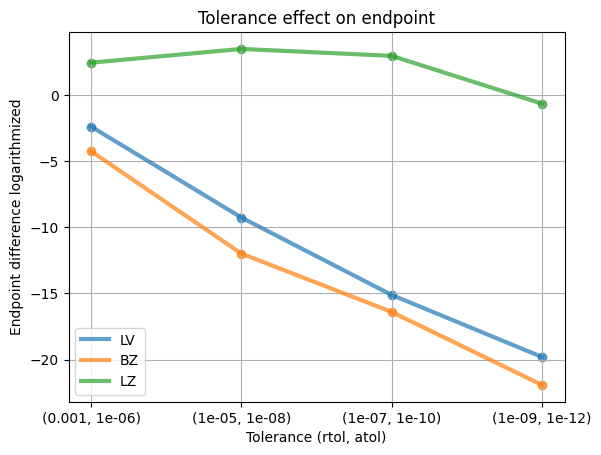

In [9]:
endPtsDiff_LV = np.linalg.norm(endPts_LV-endPts_LV[-1],axis=1)
endPtsDiff_BZ = np.linalg.norm(endPts_BZ-endPts_BZ[-1],axis=1)
endPtsDiff_LZ = np.linalg.norm(endPts_LZ-endPts_LZ[-1],axis=1)

print([f"{x:.3e}" for x in endPtsDiff_LV])
print([f"{x:.3e}" for x in endPtsDiff_BZ])
print([f"{x:.3e}" for x in endPtsDiff_LZ])

tols_s = [str(tol) for tol in tols]

plt.figure()
plt.title("Tolerance effect on endpoint")
plt.xlabel("Tolerance (rtol, atol)")
plt.ylabel("Endpoint difference logarithmized")
plt.plot(tols_s,np.log(endPtsDiff_LV),label="LV",linewidth=3, alpha=0.7)
plt.scatter(tols_s,np.log(endPtsDiff_LV), alpha=0.7)
plt.plot(tols_s,np.log(endPtsDiff_BZ),label="BZ",linewidth=3, alpha=0.7)
plt.scatter(tols_s,np.log(endPtsDiff_BZ), alpha=0.7)
plt.plot(tols_s,np.log(endPtsDiff_LZ),label="LZ",linewidth=3, alpha=0.7)
plt.scatter(tols_s,np.log(endPtsDiff_LZ), alpha=0.7)
plt.legend()
plt.grid()

# Figure text should mention endpoint difference = norm between endpoint from strictest tolerance & endpoint from each respective tolerance. 
# Strictest tolerance = (1e-11, 1e-14) 

The Lorenz system shows larger endpoint differences and weaker convergence than the other systems. This is expected as the Lorenz system is chaotic. Small errors introduced during integration will get increasingly amplified over time. Stricter tolerances can reduce the size of the errors at each step, but can not remove the systems sensitivity to small perturbations. Therefore, tightening of tolerances can delay the divergence of trajectories, but only partly mitigate it over long simulation times.


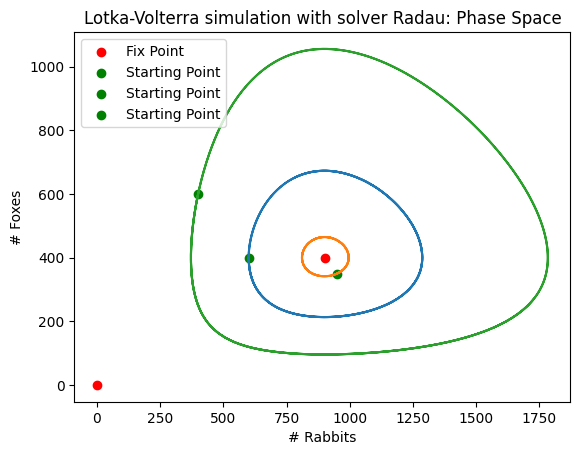

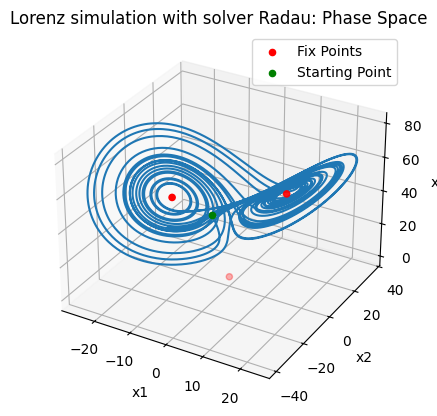

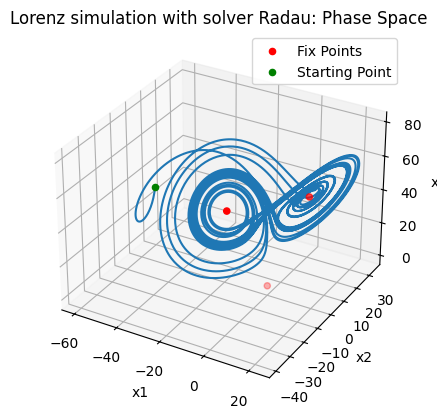

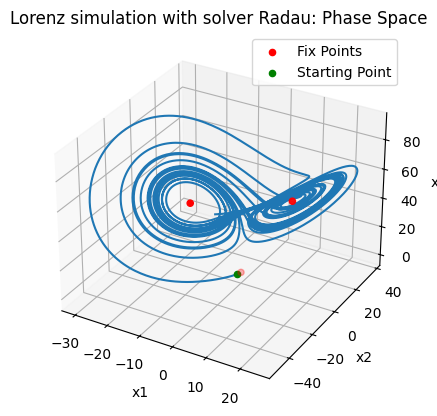

In [10]:
### Differing of Initial Conditions ###

## Lotka-Volterra ##

# Initial Conditions
y0s_LV = [[600, 400],[950,350],[400,600]]

 # Phase Diagram
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_Radau(t_plot_LV)
plt.figure()
plt.title("Lotka-Volterra simulation with solver Radau: Phase Space")
plt.xlabel("# Rabbits")
plt.ylabel("# Foxes")
plt.scatter(*fixPts_LV.T, label="Fix Point", color="r") # Fix point

for y0_LV in y0s_LV:
    sol = solve_ivp(
        fun=lotka_volterra,
        t_span=t_LV,
        y0=y0_LV,
        method='Radau',
        args=(a,b,c,d),
        dense_output=True
    )
    endPt = sol.y[:,-1]
    y_LV_Radau = sol.sol
    error_Radau = np.linalg.norm(endPt-endPt_LV_Radau)

    # Phase Diagram
    y_plot_LV = y_LV_Radau(t_plot_LV)
    plt.scatter(y_plot_LV[0,0],y_plot_LV[1,0],label="Starting Point", color="g")    
    plt.plot(y_plot_LV[0,:], y_plot_LV[1,:])

plt.legend()
plt.show()


## Lorenz ##

# Initial conditions
x0s_LZ = [[-8, 8, 27],[-60, 10, 30],[-1, -1, -1]]

for x0_LZ in x0s_LZ:
    # LZ - Radau
    sol = solve_ivp(
        fun=lorenz,
        t_span=t_Lorenz,
        y0=x0_LZ,
        method='Radau',
        args=(sigma,rho,beta_LZ),
        dense_output=True
    )
    y_LZ_Radau = sol.sol
    endPt_LZ_Radau = sol.y[:,-1]

    # Phase Diagram
    y_plot_Lorenz = y_LZ_Radau(t_plot_Lorenz)

    # Phase Diagram
    fig = plt.figure()
    ax = fig.add_subplot(111, projection="3d")

    ax.plot(
        y_plot_Lorenz[0,:],
        y_plot_Lorenz[1,:],
        y_plot_Lorenz[2,:]
    )

    # Fix Points
    ax.scatter(*fixPts_Lorenz.T, label= "Fix Points", color="r")

    ax.scatter(y_plot_Lorenz[0,0],y_plot_Lorenz[1,0],y_plot_Lorenz[2,0], label="Starting Point", color="g")
    ax.set_xlabel('x1')
    ax.set_ylabel('x2')
    ax.set_zlabel('x3')
    ax.legend()
    ax.set_title("Lorenz simulation with solver Radau: Phase Space")



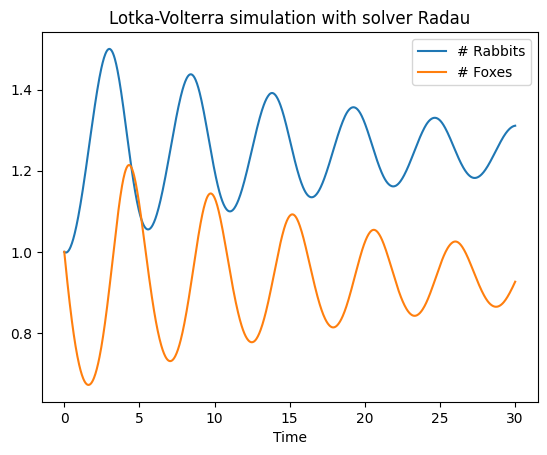

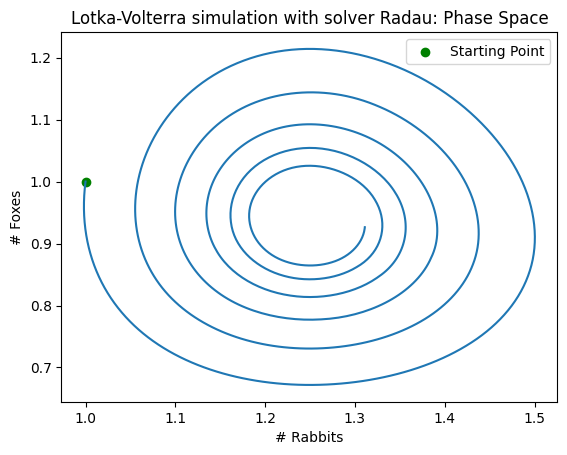

In [11]:
### Restricted dimensionless Lotka-Volterra ###

def lotka_volterra_dimensionless(t,y,alpha,r_grass,r_sat):
    r,f = y

    drdt = r*(1-r/r_grass)-r*f/(1+r/r_sat)
    dfdt = alpha*f*r/(1+r/r_sat)-alpha*f

    return [drdt, dfdt]

# Parameters
alpha = d/a
r_grass = 5
r_sat = 5

# Initial Conditions
y0_LVd = [1, 1]

# Radau
sol = solve_ivp(
    fun=lotka_volterra_dimensionless,
    t_span=t_LV,
    y0=y0_LVd,
    method='Radau',
    args=(alpha,r_grass,r_sat),
    dense_output=True
)
endPt = sol.y[:,-1]
y_LV_Radau = sol.sol
error_Radau = np.linalg.norm(endPt-endPt_LV_Radau)


# Dimensionless Lotka-Volterra Plots

# Time Series
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_Radau(t_plot_LV) # Choose method here
plt.figure()
plt.title('Lotka-Volterra simulation with solver Radau')
plt.plot(t_plot_LV, y_plot_LV[0,:],label='# Rabbits')
plt.plot(t_plot_LV, y_plot_LV[1,:],label='# Foxes')
plt.xlabel('Time')
plt.legend()
plt.show()

# Phase Diagram
plt.figure()
plt.title("Lotka-Volterra simulation with solver Radau: Phase Space")
plt.xlabel("# Rabbits")
plt.ylabel("# Foxes")
plt.plot(y_plot_LV[0,:], y_plot_LV[1,:])
#plt.scatter(*fixPts_LV.T, label="Fix Point", color="r") # Fix point
plt.scatter(y_plot_LV[0,0],y_plot_LV[1,0],label="Starting Point", color="g")
plt.legend()
plt.show()


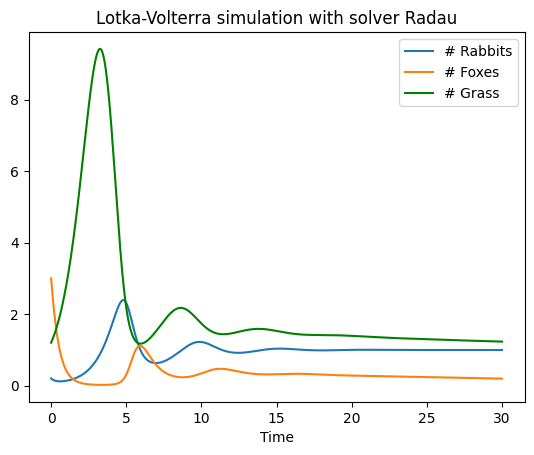

Text(0.5, 0.92, 'Lorenz simulation with solver Radau: Phase Space')

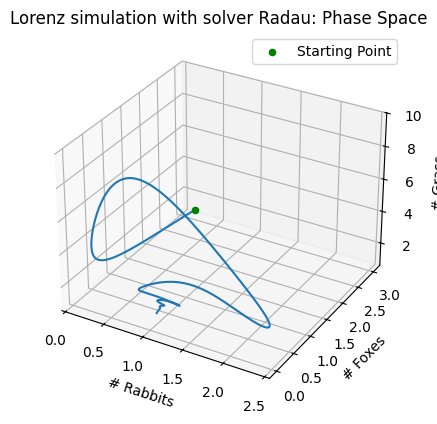

In [12]:
### Restricted dimensionless Lotka-Volterra (Grass species included) ###

def lotka_volterra_dimensionless_grass(t,y,alpha,gamma,beta,delta,r_sat,g_max):
    r,f,g = y

    drdt = r*(1-r/(gamma*g))-r*f/(1+r/(r_sat))
    dfdt = alpha*f*r/(1+r/(r_sat))-alpha*f
    dgdt = beta*g*(1-g/g_max)-delta*g*r

    return [drdt, dfdt, dgdt]

# Parameters
alpha = d/a
gamma = 1
beta_LVd = 1
delta = 1

r_sat = 80
g_max = 80

# Initial Conditions
y0_LVd = [0.2, 3, 1.2]

# Radau
sol = solve_ivp(
    fun=lotka_volterra_dimensionless_grass,
    t_span=t_LV,
    y0=y0_LVd,
    method='Radau',
    args=(alpha,beta_LVd,gamma,delta,r_sat,g_max),
    dense_output=True
)
endPt = sol.y[:,-1]
y_LV_Radau = sol.sol

# Dimensionless Lotka-Volterra (with grass) Plots

# Time Series
t_plot_LV = np.linspace(t_LV[0], t_LV[1], 1000)
y_plot_LV = y_LV_Radau(t_plot_LV) # Choose method here
plt.figure()
plt.title('Lotka-Volterra simulation with solver Radau')
plt.plot(t_plot_LV, y_plot_LV[0,:],label='# Rabbits')
plt.plot(t_plot_LV, y_plot_LV[1,:],label='# Foxes')
plt.plot(t_plot_LV, y_plot_LV[2,:],label='# Grass', color="g")
plt.xlabel('Time')
plt.legend()
plt.show()


# Phase Diagram
fig = plt.figure()
ax = fig.add_subplot(111, projection="3d")

ax.plot(
    y_plot_LV[0,:],
    y_plot_LV[1,:],
    y_plot_LV[2,:]
)

# Fix Points
#ax.scatter(*fixPts_Lorenz.T, label= "Fix Points", color="r")

ax.scatter(y_plot_LV[0,0],y_plot_LV[1,0],y_plot_LV[2,0], label="Starting Point", color="g")
ax.set_xlabel('# Rabbits')
ax.set_ylabel('# Foxes')
ax.set_zlabel('# Grass')
ax.legend()
ax.set_title("Lorenz simulation with solver Radau: Phase Space")

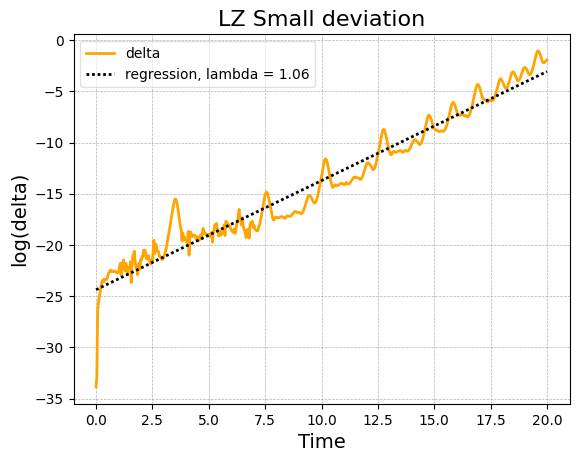

In [53]:
### Lorenz Initial Condition Perturbation ###

t = np.linspace(t_Lorenz[0],t_Lorenz[1],len(y_Lorenz_diff))

# Initial conditions
pert = 1e-15
x0_LZ = [-8, 8, 27]
x0_LZ_pert = [-8+pert,8+pert,27+pert]

sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0_LZ,
    args = (sigma, rho, beta_LZ),
    method = "Radau",
    dense_output=True
)
y_Lorenz = sol.sol(t)

sol = solve_ivp(
    fun = lorenz,
    t_span = t_Lorenz,
    y0 = x0_LZ_pert,
    args = (sigma, rho, beta_LZ),
    method = "Radau",
    dense_output=True
)
y_Lorenz_pert = sol.sol(t)

y_Lorenz_diff = np.linalg.norm(y_Lorenz-y_Lorenz_pert,axis=0)
pf = np.polyfit(t,np.log(y_Lorenz_diff),deg=1)
pv = np.poly1d(pf)

plt.figure()
plt.plot(t,np.log(y_Lorenz_diff), label = "delta", linewidth = 2, color = "orange")
plt.plot(t,pv(t), label = "regression, lambda = 1.06", linewidth = 2, color = "black", linestyle = (0,(1,1)), zorder = 10)
plt.title("LZ Small deviation", fontsize = 16)
plt.xlabel("Time", fontsize = 14)
plt.ylabel("log(delta)", fontsize = 14)
plt.legend(fontsize=10, framealpha=0.6)
plt.grid(True, linestyle="--", color="grey", linewidth=0.5, alpha=0.6)
plt.savefig("LZ_reg.pdf", dpi=300)
